
# Techno-Economic Modelling and Performance Assessment of a Grid-Connected Solar PV–Battery System

**Author:** Chibuzor Victor Obih

**Year:** 2026

## 1. Project Overview

This project develops a simplified Python-based computational model of a grid-connected solar photovoltaic (PV) and battery energy storage system supplying electricity to a hypothetical small building.

The model investigates the relationship between hourly building electricity demand, solar PV generation, battery charging and discharging, and electricity imported from the utility grid.

## 2. Project Objectives

1. Model hourly electricity consumption and solar PV generation.
2. Simulate battery energy storage and state of charge.
3. Compare grid-only, solar PV-only and solar PV–battery scenarios.
4. Estimate electricity costs and operational carbon emissions.
5. Conduct sensitivity analyses for selected system parameters.

## 3. Project Scope

The study uses illustrative building electricity demand and solar radiation profiles.

A simplified hourly energy-balance approach will be implemented using Python.

The project is intended for educational and portfolio purposes and does not represent the validated design of an actual electrical installation.


In [109]:

# Import libraries for solar PV-battery modelling

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully!")


Libraries imported successfully!


In [163]:

# Identify the main project directory

current_folder = Path.cwd()

if current_folder.name == "notebooks":
    project_folder = current_folder.parent
else:
    project_folder = current_folder

# Define project subfolders

data_folder = project_folder / "data"
figures_folder = project_folder / "figures"
documentation_folder = project_folder / "documentation"

# Ensure the folders exist

for folder in [data_folder, figures_folder, documentation_folder]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directories configured successfully!")


Project directories configured successfully!


In [164]:

# Create a 24-hour simulation timeline

hours = np.arange(0, 24, 1)

# Create a DataFrame for hourly data

energy_data = pd.DataFrame({
    "Hour": hours
})

# Display the hourly timeline

display(energy_data)


,Hour
0,0
1,1
2,2
3,3
4,4
5,5
6,6
7,7
8,8
9,9



## 4. Hourly Building Electricity Demand

This section develops an illustrative 24-hour electricity-demand profile for a hypothetical small building.

Electricity demand varies throughout the day due to changing building activities and equipment operation.

The demand values are assumed for educational modelling and do not represent measured building electricity consumption.

Electrical energy consumption is calculated using:

E = P × t

where:
- E = Electrical energy consumption (kWh)
- P = Average electrical power (kW)
- t = Time interval (hours)

A one-hour simulation interval is adopted.


In [165]:

# Define illustrative hourly building power demand (kW)

hourly_demand_kw = np.array([
    0.6, 0.5, 0.5, 0.5, 0.5, 0.7,
    0.9, 1.2, 1.6, 1.9, 2.1, 2.2,
    2.3, 2.4, 2.2, 2.1, 2.0, 2.3,
    2.5, 2.4, 1.9, 1.5, 1.1, 0.8
])

# Add demand to our existing 24-hour DataFrame

energy_data["Demand_kW"] = hourly_demand_kw

# Calculate electricity consumed during each hour

time_step_hours = 1

energy_data["Demand_kWh"] = (
    energy_data["Demand_kW"] * time_step_hours
)

# Display the updated table

display(energy_data)


,Hour,Demand_kW,Demand_kWh
0,0,0.6,0.6
1,1,0.5,0.5
2,2,0.5,0.5
3,3,0.5,0.5
4,4,0.5,0.5
5,5,0.7,0.7
6,6,0.9,0.9
7,7,1.2,1.2
8,8,1.6,1.6
9,9,1.9,1.9


In [166]:

# Calculate daily electricity consumption

daily_demand_kwh = energy_data["Demand_kWh"].sum()

# Calculate average power demand

average_demand_kw = energy_data["Demand_kW"].mean()

# Calculate peak power demand

peak_demand_kw = energy_data["Demand_kW"].max()

peak_hour = energy_data.loc[
    energy_data["Demand_kW"].idxmax(), "Hour"
]

print(f"Daily electricity consumption: {daily_demand_kwh:.2f} kWh")
print(f"Average power demand: {average_demand_kw:.2f} kW")
print(f"Peak power demand: {peak_demand_kw:.2f} kW")
print(f"Peak demand occurs at hour: {peak_hour}")


Daily electricity consumption: 36.70 kWh
Average power demand: 1.53 kW
Peak power demand: 2.50 kW
Peak demand occurs at hour: 18


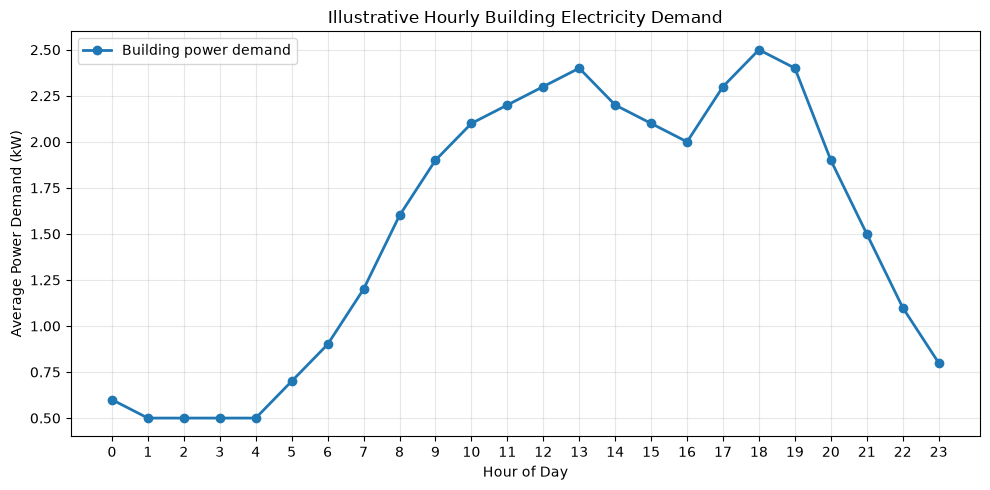

In [167]:

# Plot hourly building power demand

plt.figure(figsize=(10, 5))

plt.plot(
    energy_data["Hour"],
    energy_data["Demand_kW"],
    marker="o",
    linewidth=2,
    label="Building power demand"
)

plt.xlabel("Hour of Day")
plt.ylabel("Average Power Demand (kW)")

plt.title("Illustrative Hourly Building Electricity Demand")

plt.xticks(np.arange(0, 24, 1))
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

# Save the graph

plt.savefig(
    figures_folder / "hourly_building_demand.png",
    dpi=300
)

plt.show()


In [168]:

# Verify that our dataset contains 24 hourly intervals

assert len(energy_data) == 24

assert (energy_data["Demand_kW"] >= 0).all()

assert np.isclose(
    energy_data["Demand_kWh"].sum(),
    36.70
)

# Save the hourly electricity-demand dataset

energy_data.to_csv(
    data_folder / "hourly_building_demand.csv",
    index=False
)

print("Dataset verified and saved successfully!")


Dataset verified and saved successfully!



### Results and Discussion

The illustrative building electricity-demand model produced a total daily consumption of 36.70 kWh.

The average power demand was approximately 1.53 kW, while the maximum hourly average demand was 2.50 kW during the 18:00–19:00 interval.

Electricity demand was relatively low during the early morning hours and increased during periods of assumed building activity.

The resulting hourly demand profile will serve as an input to the solar PV generation and battery storage models.

### Assumptions and Limitations

1. All electricity-demand values are hypothetical.
2. The simulation uses a one-hour time step.
3. Power demand is assumed constant within each hourly interval.
4. Seasonal and weekday variations are not considered at this stage.
5. The model is intended for educational energy-system analysis rather than actual building electrical design.



## 5. Solar PV Electricity Generation Model

This section estimates hourly solar photovoltaic electricity generation for a hypothetical 5 kWp solar PV system.

An illustrative 24-hour solar irradiance profile is used to investigate the variation in solar electricity production.

Solar PV power generation is estimated using:

P_PV = P_rated × (G / G_ref) × PR

where:

- P_PV = Solar PV power output (kW)
- P_rated = Installed PV capacity (kWp)
- G = Hourly average solar irradiance (W/m²)
- G_ref = Reference solar irradiance (1000 W/m²)
- PR = Assumed PV performance factor (0.80)

All irradiance values are hypothetical and are not measurements from an actual location.


In [169]:

# Define illustrative hourly solar irradiance (W/m²)

solar_irradiance = np.array([
    0, 0, 0, 0, 0, 0,
    80, 200, 400, 600, 760, 880,
    950, 900, 800, 650, 450, 230,
    60, 0, 0, 0, 0, 0
])

# Add solar irradiance to our existing DataFrame

energy_data["Irradiance_Wm2"] = solar_irradiance

# Display the updated dataset

display(energy_data)


,Hour,Demand_kW,Demand_kWh,Irradiance_Wm2
0,0,0.6,0.6,0
1,1,0.5,0.5,0
2,2,0.5,0.5,0
3,3,0.5,0.5,0
4,4,0.5,0.5,0
5,5,0.7,0.7,0
6,6,0.9,0.9,80
7,7,1.2,1.2,200
8,8,1.6,1.6,400
9,9,1.9,1.9,600


In [170]:

# Define solar PV system parameters

pv_capacity_kwp = 5.0
reference_irradiance = 1000
pv_performance_factor = 0.80

# Calculate hourly solar PV power output (kW)

energy_data["PV_Generation_kW"] = (
    pv_capacity_kwp
    * (energy_data["Irradiance_Wm2"] / reference_irradiance)
    * pv_performance_factor
)

# Calculate energy generated during each hour (kWh)

energy_data["PV_Generation_kWh"] = (
    energy_data["PV_Generation_kW"] * time_step_hours
)

# Display the updated solar PV calculations

display(
    energy_data[
        [
            "Hour",
            "Irradiance_Wm2",
            "PV_Generation_kW",
            "PV_Generation_kWh"
        ]
    ]
)


,Hour,Irradiance_Wm2,PV_Generation_kW,PV_Generation_kWh
0,0,0,0.00,0.00
1,1,0,0.00,0.00
2,2,0,0.00,0.00
3,3,0,0.00,0.00
4,4,0,0.00,0.00
5,5,0,0.00,0.00
6,6,80,0.32,0.32
7,7,200,0.80,0.80
8,8,400,1.60,1.60
9,9,600,2.40,2.40


In [171]:

# Calculate total daily solar PV generation

daily_pv_generation_kwh = (
    energy_data["PV_Generation_kWh"].sum()
)

# Calculate peak PV power output

peak_pv_power_kw = (
    energy_data["PV_Generation_kW"].max()
)

# Identify the hour with maximum PV generation

peak_pv_hour = energy_data.loc[
    energy_data["PV_Generation_kW"].idxmax(),
    "Hour"
]

# Display the results

print(f"Total daily PV generation: {daily_pv_generation_kwh:.2f} kWh")
print(f"Peak PV power output: {peak_pv_power_kw:.2f} kW")
print(f"Peak PV generation occurs at hour: {peak_pv_hour}")


Total daily PV generation: 27.84 kWh
Peak PV power output: 3.80 kW
Peak PV generation occurs at hour: 12


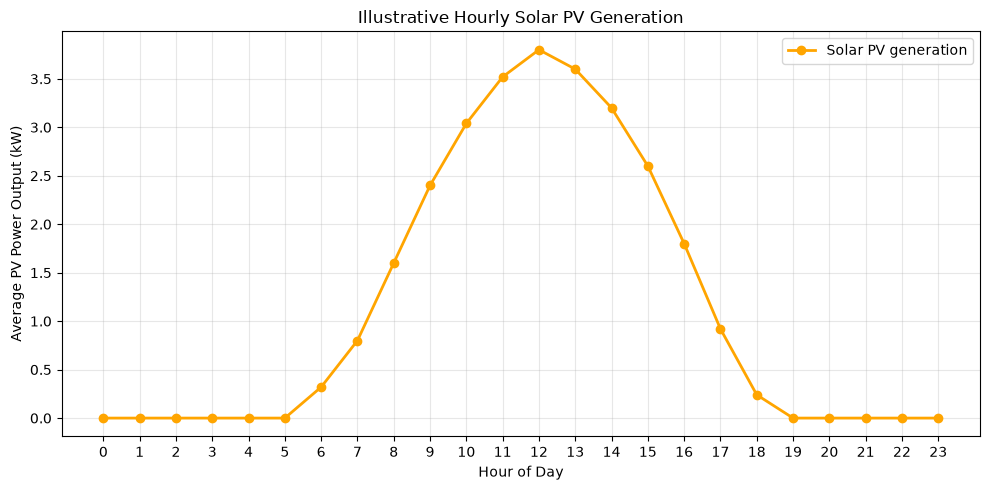

In [172]:

# Plot hourly solar PV power generation

plt.figure(figsize=(10, 5))

plt.plot(
    energy_data["Hour"],
    energy_data["PV_Generation_kW"],
    marker="o",
    linewidth=2,
    color="orange",
    label="Solar PV generation"
)

plt.xlabel("Hour of Day")
plt.ylabel("Average PV Power Output (kW)")

plt.title("Illustrative Hourly Solar PV Generation")

plt.xticks(np.arange(0, 24, 1))
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

# Save the figure

plt.savefig(
    figures_folder / "hourly_pv_generation.png",
    dpi=300
)

plt.show()


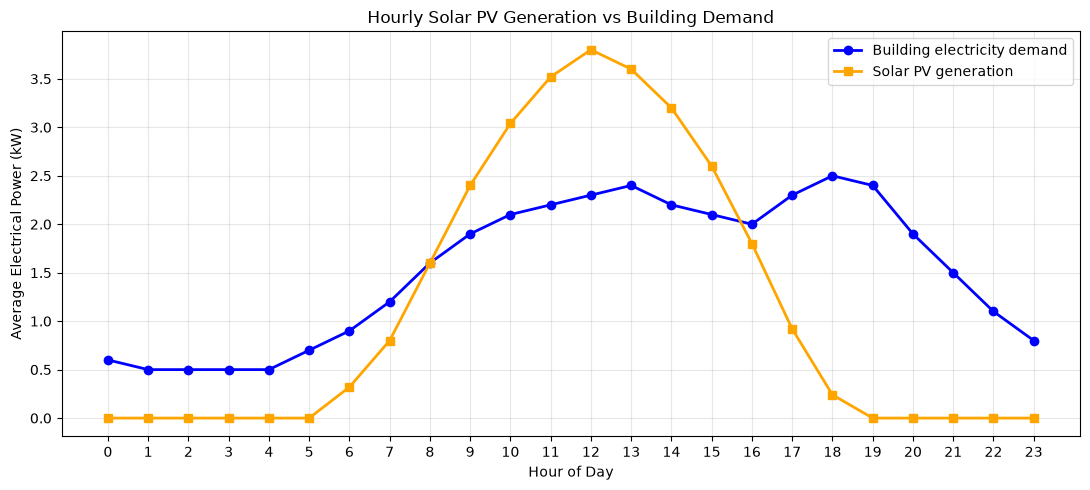

In [173]:

# Compare hourly building demand and solar PV generation

plt.figure(figsize=(11, 5))

# Building electricity demand

plt.plot(
    energy_data["Hour"],
    energy_data["Demand_kW"],
    marker="o",
    linewidth=2,
    color="blue",
    label="Building electricity demand"
)

# Solar PV generation

plt.plot(
    energy_data["Hour"],
    energy_data["PV_Generation_kW"],
    marker="s",
    linewidth=2,
    color="orange",
    label="Solar PV generation"
)

plt.xlabel("Hour of Day")
plt.ylabel("Average Electrical Power (kW)")

plt.title("Hourly Solar PV Generation vs Building Demand")

plt.xticks(np.arange(0, 24, 1))
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

# Save comparison figure

plt.savefig(
    figures_folder / "pv_vs_building_demand.png",
    dpi=300
)

plt.show()


In [174]:

# Verify the solar PV model

assert len(energy_data) == 24

# PV generation cannot be negative

assert (
    energy_data["PV_Generation_kW"] >= 0
).all()

# Output must not exceed assumed derated PV capacity

assert (
    energy_data["PV_Generation_kW"]
    <= pv_capacity_kwp * pv_performance_factor + 1e-9
).all()

# Verify daily PV energy generation

assert np.isclose(
    daily_pv_generation_kwh,
    27.84
)

# Verify hourly power-to-energy conversion

assert np.allclose(
    energy_data["PV_Generation_kWh"],
    energy_data["PV_Generation_kW"] * time_step_hours
)

# Save our combined electricity dataset

energy_data.to_csv(
    data_folder / "hourly_energy_profiles.csv",
    index=False
)

print("Solar PV calculations verified successfully!")
print("Combined energy dataset saved successfully!")


Solar PV calculations verified successfully!
Combined energy dataset saved successfully!



## 6. Solar PV Generation Results and Discussion

The simplified solar PV model estimated a total daily electricity generation of 27.84 kWh from an installed capacity of 5 kWp.

The maximum hourly average PV power output was 3.80 kW, occurring during the 12:00–13:00 interval.

Comparison with the illustrative building electricity-demand profile showed that solar PV generation exceeded demand during several daytime hours.

However, during the early morning and evening, building electricity demand exceeded solar generation.

This mismatch highlights the potential role of battery energy storage in improving solar electricity utilisation.

## Assumptions and Limitations

1. The solar irradiance profile is hypothetical.
2. A constant PV performance factor of 0.80 is assumed.
3. The simulation uses a one-hour time step.
4. Solar PV power is estimated using a simplified irradiance-based equation.
5. Detailed temperature, inverter, shading and orientation effects are not modelled separately.
6. The results do not represent verified solar electricity production at a real location.
7. Battery storage and grid electricity exchanges will be modelled separately.

The results demonstrate the importance of matching renewable electricity generation with building consumption.



## 7. Battery Energy Storage and Grid Interaction

This section develops a simplified hourly battery dispatch model for a grid-connected solar PV–battery system.

The model follows a solar-first operating strategy:

1. Solar PV generation supplies building demand.
2. Excess solar electricity charges the battery.
3. The battery supplies electricity when PV generation is insufficient.
4. The utility grid supplies any remaining demand.
5. Unused solar electricity is curtailed.

Battery charging and discharging efficiencies are included.

The battery is operated between minimum and maximum state-of-charge limits.

The model uses hypothetical system parameters and does not represent a validated battery installation.


In [175]:

# Battery energy storage parameters

battery_capacity_kwh = 10.0

soc_initial_pct = 50.0
soc_min_pct = 20.0
soc_max_pct = 90.0

charge_efficiency = 0.95
discharge_efficiency = 0.95

# Convert SOC percentages to stored energy (kWh)

initial_storage_kwh = (
    battery_capacity_kwh * soc_initial_pct / 100
)

min_storage_kwh = (
    battery_capacity_kwh * soc_min_pct / 100
)

max_storage_kwh = (
    battery_capacity_kwh * soc_max_pct / 100
)

# Set the initial battery energy

battery_stored_kwh = initial_storage_kwh

print(f"Initial battery energy: {initial_storage_kwh:.2f} kWh")
print(f"Minimum battery energy: {min_storage_kwh:.2f} kWh")
print(f"Maximum battery energy: {max_storage_kwh:.2f} kWh")


Initial battery energy: 5.00 kWh
Minimum battery energy: 2.00 kWh
Maximum battery energy: 9.00 kWh


In [176]:

# Hourly solar PV-battery-grid simulation

# Start the battery at its assumed initial energy
battery_stored_kwh = initial_storage_kwh

# Store the results from each simulated hour
records = []

for _, row in energy_data.iterrows():

    # Energy demand and PV supply during this hour
    demand = float(row["Demand_kWh"])
    pv = float(row["PV_Generation_kWh"])

    # 1. Use solar PV to supply building demand first
    pv_to_load = min(demand, pv)

    pv_surplus = max(0.0, pv - pv_to_load)
    remaining_load = max(0.0, demand - pv_to_load)

    # 2. Charge battery with surplus PV electricity
    room_for_charge_input = max(
        0.0,
        (max_storage_kwh - battery_stored_kwh)
        / charge_efficiency
    )

    pv_to_battery = min(
        pv_surplus,
        room_for_charge_input
    )

    battery_stored_kwh += (
        pv_to_battery * charge_efficiency
    )

    # 3. Discharge battery when PV is insufficient
    available_battery_output = max(
        0.0,
        (battery_stored_kwh - min_storage_kwh)
        * discharge_efficiency
    )

    battery_to_load = min(
        remaining_load,
        available_battery_output
    )

    battery_stored_kwh -= (
        battery_to_load / discharge_efficiency
    )

    # 4. Import remaining electricity from the grid
    grid_import = max(
        0.0,
        remaining_load - battery_to_load
    )

    # 5. Account for unused solar electricity
    pv_curtailed = max(
        0.0,
        pv_surplus - pv_to_battery
    )

    # 6. Calculate battery state of charge
    battery_soc_pct = (
        battery_stored_kwh
        / battery_capacity_kwh
        * 100
    )

    # 7. Calculate battery efficiency losses
    charge_loss = (
        pv_to_battery * (1 - charge_efficiency)
    )

    discharge_loss = (
        battery_to_load
        * (1 / discharge_efficiency - 1)
    )

    # 8. Record the results for this hour
    records.append({
        "PV_to_Load_kWh": pv_to_load,
        "PV_to_Battery_kWh": pv_to_battery,
        "Battery_to_Load_kWh": battery_to_load,
        "Grid_Import_kWh": grid_import,
        "PV_Curtailed_kWh": pv_curtailed,
        "Battery_Stored_kWh": battery_stored_kwh,
        "Battery_SOC_pct": battery_soc_pct,
        "Charge_Loss_kWh": charge_loss,
        "Discharge_Loss_kWh": discharge_loss
    })

# Convert the results to a DataFrame
sim_results = pd.DataFrame(records)

# Add simulation results to our existing data
for column in sim_results.columns:
    energy_data[column] = sim_results[column]

print("24-hour battery simulation completed!")

display(energy_data.round(3))


24-hour battery simulation completed!


,Hour,Demand_kW,Demand_kWh,Irradiance_Wm2,PV_Generation_kW,PV_Generation_kWh,PV_to_Load_kWh,PV_to_Battery_kWh,Battery_to_Load_kWh,Grid_Import_kWh,PV_Curtailed_kWh,Battery_Stored_kWh,Battery_SOC_pct,Charge_Loss_kWh,Discharge_Loss_kWh
0,0,0.6,0.6,0,0.00,0.00,0.00,0.00,0.600,0.000,0.0,4.368,43.684,0.000,0.032
1,1,0.5,0.5,0,0.00,0.00,0.00,0.00,0.500,0.000,0.0,3.842,38.421,0.000,0.026
2,2,0.5,0.5,0,0.00,0.00,0.00,0.00,0.500,0.000,0.0,3.316,33.158,0.000,0.026
3,3,0.5,0.5,0,0.00,0.00,0.00,0.00,0.500,0.000,0.0,2.789,27.895,0.000,0.026
4,4,0.5,0.5,0,0.00,0.00,0.00,0.00,0.500,0.000,0.0,2.263,22.632,0.000,0.026
5,5,0.7,0.7,0,0.00,0.00,0.00,0.00,0.250,0.450,0.0,2.000,20.000,0.000,0.013
6,6,0.9,0.9,80,0.32,0.32,0.32,0.00,0.000,0.580,0.0,2.000,20.000,0.000,0.000
7,7,1.2,1.2,200,0.80,0.80,0.80,0.00,0.000,0.400,0.0,2.000,20.000,0.000,0.000
8,8,1.6,1.6,400,1.60,1.60,1.60,0.00,0.000,0.000,0.0,2.000,20.000,0.000,0.000
9,9,1.9,1.9,600,2.40,2.40,1.90,0.50,0.000,0.000,0.0,2.475,24.750,0.025,0.000


In [177]:

# Calculate daily energy totals

total_demand = energy_data["Demand_kWh"].sum()

total_pv = energy_data["PV_Generation_kWh"].sum()

total_pv_direct = energy_data["PV_to_Load_kWh"].sum()

total_battery_charging = energy_data[
    "PV_to_Battery_kWh"
].sum()

total_battery_discharge = energy_data[
    "Battery_to_Load_kWh"
].sum()

total_grid_import = energy_data[
    "Grid_Import_kWh"
].sum()

total_pv_curtailed = energy_data[
    "PV_Curtailed_kWh"
].sum()

final_soc = energy_data["Battery_SOC_pct"].iloc[-1]

# Display performance results

print(f"Daily building demand: {total_demand:.2f} kWh")
print(f"Total solar generation: {total_pv:.2f} kWh")
print(f"PV directly serving load: {total_pv_direct:.2f} kWh")
print(f"PV supplied to battery: {total_battery_charging:.2f} kWh")
print(f"Battery energy delivered: {total_battery_discharge:.2f} kWh")
print(f"Grid electricity imported: {total_grid_import:.2f} kWh")
print(f"Curtailed PV energy: {total_pv_curtailed:.2f} kWh")
print(f"Final battery SOC: {final_soc:.2f}%")


Daily building demand: 36.70 kWh
Total solar generation: 27.84 kWh
PV directly serving load: 20.88 kWh
PV supplied to battery: 6.96 kWh
Battery energy delivered: 9.13 kWh
Grid electricity imported: 6.69 kWh
Curtailed PV energy: 0.00 kWh
Final battery SOC: 20.00%


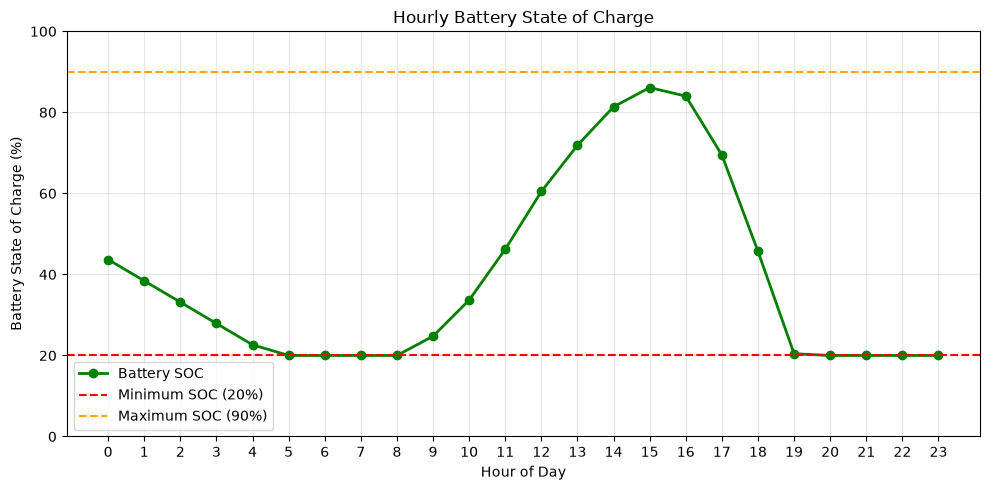

In [178]:

# Plot hourly battery state of charge

plt.figure(figsize=(10, 5))

plt.plot(
    energy_data["Hour"],
    energy_data["Battery_SOC_pct"],
    marker="o",
    linewidth=2,
    color="green",
    label="Battery SOC"
)

# Show minimum and maximum SOC limits
plt.axhline(
    y=soc_min_pct,
    color="red",
    linestyle="--",
    label="Minimum SOC (20%)"
)

plt.axhline(
    y=soc_max_pct,
    color="orange",
    linestyle="--",
    label="Maximum SOC (90%)"
)

plt.xlabel("Hour of Day")
plt.ylabel("Battery State of Charge (%)")

plt.title("Hourly Battery State of Charge")

plt.xticks(np.arange(0, 24, 1))
plt.ylim(0, 100)

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    figures_folder / "battery_soc_profile.png",
    dpi=300
)

plt.show()


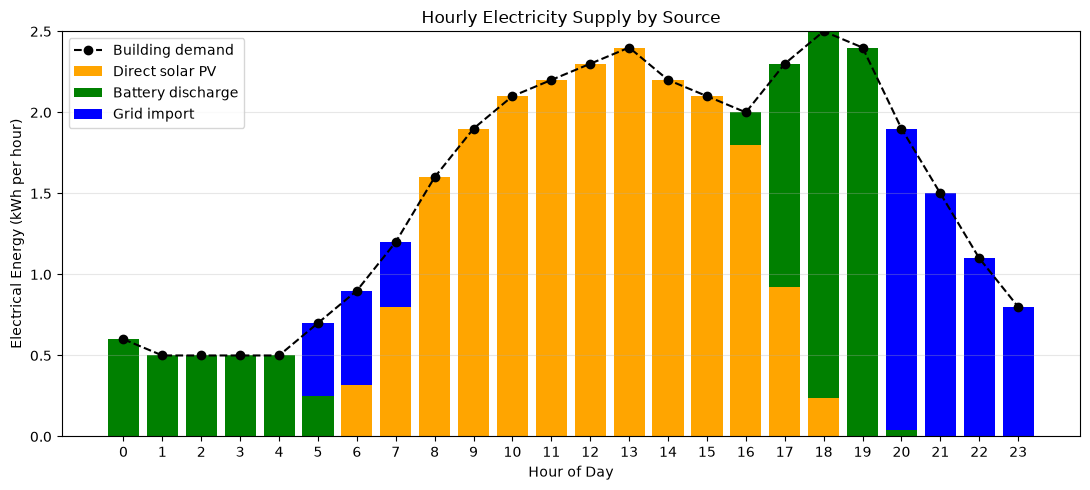

In [179]:

# Plot hourly electricity supply by source

plt.figure(figsize=(11, 5))

hours = energy_data["Hour"]

pv_supply = energy_data["PV_to_Load_kWh"]
battery_supply = energy_data["Battery_to_Load_kWh"]
grid_supply = energy_data["Grid_Import_kWh"]

# Direct solar electricity
plt.bar(
    hours,
    pv_supply,
    color="orange",
    label="Direct solar PV"
)

# Battery electricity
plt.bar(
    hours,
    battery_supply,
    bottom=pv_supply,
    color="green",
    label="Battery discharge"
)

# Grid electricity
plt.bar(
    hours,
    grid_supply,
    bottom=pv_supply + battery_supply,
    color="blue",
    label="Grid import"
)

# Building electricity demand
plt.plot(
    hours,
    energy_data["Demand_kWh"],
    color="black",
    linestyle="--",
    marker="o",
    label="Building demand"
)

plt.xlabel("Hour of Day")
plt.ylabel("Electrical Energy (kWh per hour)")

plt.title("Hourly Electricity Supply by Source")

plt.xticks(np.arange(0, 24, 1))
plt.grid(True, axis="y", alpha=0.3)

plt.legend()
plt.tight_layout()

plt.savefig(
    figures_folder / "hourly_electricity_supply.png",
    dpi=300
)

plt.show()


In [180]:

# Compare grid electricity imports

# Scenario A: Grid only
grid_only_kwh = energy_data["Demand_kWh"].sum()

# Scenario B: Solar PV without battery
pv_only_grid_kwh = np.maximum(
    energy_data["Demand_kWh"]
    - energy_data["PV_Generation_kWh"],
    0
).sum()

# Scenario C: Solar PV with battery
pv_battery_grid_kwh = energy_data[
    "Grid_Import_kWh"
].sum()

scenario_results = pd.DataFrame({
    "Scenario": [
        "Grid Only",
        "Grid + Solar PV",
        "Grid + Solar PV + Battery"
    ],
    "Grid_Import_kWh": [
        grid_only_kwh,
        pv_only_grid_kwh,
        pv_battery_grid_kwh
    ]
})

display(scenario_results.round(2))


,Scenario,Grid_Import_kWh
0,Grid Only,36.70
1,Grid + Solar PV,15.82
2,Grid + Solar PV + Battery,6.69


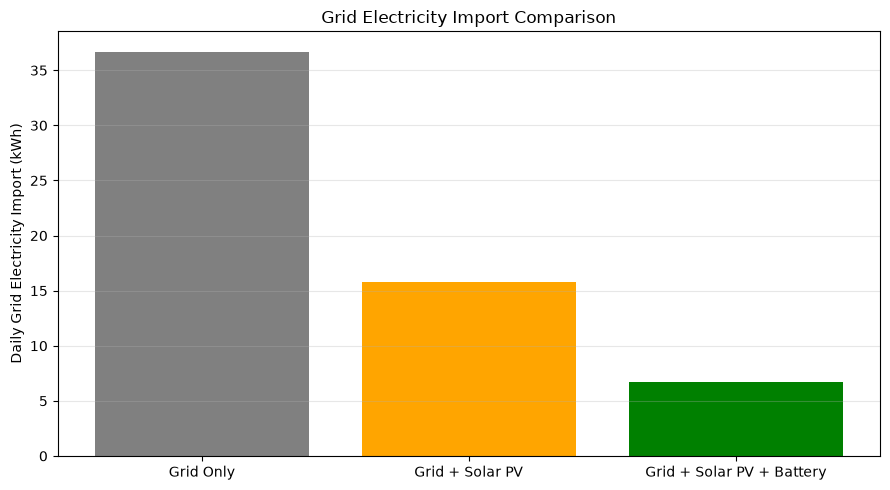

In [181]:

# Plot grid electricity comparison

plt.figure(figsize=(9, 5))

plt.bar(
    scenario_results["Scenario"],
    scenario_results["Grid_Import_kWh"],
    color=["gray", "orange", "green"]
)

plt.ylabel("Daily Grid Electricity Import (kWh)")
plt.title("Grid Electricity Import Comparison")

plt.grid(True, axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_folder / "grid_import_comparison.png",
    dpi=300
)

plt.show()


In [182]:

# Verify hourly building energy balance

np.testing.assert_allclose(
    energy_data["Demand_kWh"],
    energy_data["PV_to_Load_kWh"]
    + energy_data["Battery_to_Load_kWh"]
    + energy_data["Grid_Import_kWh"],
    atol=1e-9
)

# Verify hourly solar PV energy balance

np.testing.assert_allclose(
    energy_data["PV_Generation_kWh"],
    energy_data["PV_to_Load_kWh"]
    + energy_data["PV_to_Battery_kWh"]
    + energy_data["PV_Curtailed_kWh"],
    atol=1e-9
)

# Verify battery storage boundaries

assert (
    energy_data["Battery_Stored_kWh"]
    >= min_storage_kwh - 1e-9
).all()

assert (
    energy_data["Battery_Stored_kWh"]
    <= max_storage_kwh + 1e-9
).all()

# Verify overall energy conservation

total_energy_input = (
    total_pv
    + total_grid_import
    + initial_storage_kwh
)

total_energy_output = (
    total_demand
    + total_pv_curtailed
    + energy_data["Charge_Loss_kWh"].sum()
    + energy_data["Discharge_Loss_kWh"].sum()
    + battery_stored_kwh
)

energy_balance_error = (
    total_energy_input - total_energy_output
)

assert np.isclose(
    total_energy_input,
    total_energy_output,
    atol=1e-9
)

print("All energy-balance checks passed!")
print(f"Energy-balance error: {energy_balance_error:.10f} kWh")


All energy-balance checks passed!
Energy-balance error: 0.0000000000 kWh


In [183]:

# Save complete hourly simulation results

energy_data.to_csv(
    data_folder / "pv_battery_grid_simulation.csv",
    index=False
)

# Save scenario comparison

scenario_results.to_csv(
    data_folder / "scenario_comparison.csv",
    index=False
)

print("Simulation datasets saved successfully!")


Simulation datasets saved successfully!



## 8. Battery and Grid Simulation Results

A simplified hourly energy-management model was developed for the hypothetical grid-connected solar PV–battery system.

The model prioritised direct solar electricity consumption, followed by battery charging or discharging and grid electricity imports.

The assumed 10 kWh battery operated between 20% and 90% state of charge, with charging and discharging efficiencies of 95%.

### Results

The simulated building consumed 36.70 kWh over 24 hours, while solar PV generation totalled 27.84 kWh.

Direct solar PV consumption supplied 20.88 kWh, while 6.96 kWh of surplus PV electricity was sent to the battery.

The battery delivered approximately 9.13 kWh to the building, and grid electricity imports totalled approximately 6.69 kWh.

The battery began at 50% state of charge and finished at 20%.

### Scenario Comparison

Daily grid electricity imports were:

- Grid-only: 36.70 kWh
- Grid with solar PV: 15.82 kWh
- Grid with solar PV and battery: 6.69 kWh

These figures describe a single illustrative day and should not be interpreted as recurring daily savings because the battery began and ended with different stored-energy levels.

### Model Verification

Hourly electricity-demand balances and PV energy balances were checked.

The battery remained within the defined storage limits.

Overall energy conservation was verified while accounting for battery losses and the difference between initial and final stored energy.

### Limitations

1. Electricity demand and solar irradiance are hypothetical.
2. The model uses hourly average electricity demand and PV generation.
3. Battery charging and discharging power limits are not included.
4. Battery degradation and detailed inverter behaviour are not considered.
5. Grid electricity is assumed continuously available.
6. Grid export is not permitted.
7. Long-term performance requires additional simulation and consistent initial and final storage conditions.

Further analysis will examine operating costs, carbon emissions and sensitivity to system parameters.



## 9. Repeating-Day Battery Simulation

The initial 24-hour simulation began with the battery at 50% state of charge and ended at 20%.

This difference represents a net reduction in stored battery energy.

To avoid overestimating the recurring reduction in grid electricity consumption, a repeating-day simulation is introduced.

The same illustrative electricity-demand and solar-generation profiles are repeated until the initial and final battery energy values are equal within a specified numerical tolerance.

The resulting daily cycle provides a consistent basis for comparing the grid-only, solar PV-only and solar PV–battery configurations.

This approach assumes identical daily conditions and does not account for seasonal variations.


In [184]:

# Repeating-day battery model

# Define battery parameters

capacity_kwh = 10.0
min_soc = 20.0
max_soc = 90.0

eta_charge = 0.95
eta_discharge = 0.95

# Define battery simulation function

def simulate_one_day(df, starting_energy_kwh):

    stored = starting_energy_kwh

    min_energy = capacity_kwh * min_soc / 100
    max_energy = capacity_kwh * max_soc / 100

    rows = []

    for _, hour in df.iterrows():

        demand = float(hour["Demand_kWh"])
        solar = float(hour["PV_Generation_kWh"])

        beginning_energy = stored

        # Direct solar electricity to building
        pv_to_load = min(demand, solar)

        excess_solar = max(0, solar - pv_to_load)
        unmet_demand = max(0, demand - pv_to_load)

        # Charge battery with available excess PV
        battery_charge_input = min(
            excess_solar,
            max(0, (max_energy - stored) / eta_charge)
        )

        stored += battery_charge_input * eta_charge

        # Discharge battery to meet remaining demand
        battery_discharge_output = min(
            unmet_demand,
            max(0, (stored - min_energy) * eta_discharge)
        )

        stored -= battery_discharge_output / eta_discharge

        # Calculate grid electricity import
        grid_import = max(
            0,
            unmet_demand - battery_discharge_output
        )

        # Calculate curtailed solar electricity
        pv_curtailed = max(
            0,
            excess_solar - battery_charge_input
        )

        # Record hourly results
        rows.append({
            "Hour": int(hour["Hour"]),
            "Demand_kWh": demand,
            "PV_Generation_kWh": solar,
            "PV_to_Load_kWh": pv_to_load,
            "PV_to_Battery_kWh": battery_charge_input,
            "Battery_to_Load_kWh": battery_discharge_output,
            "Grid_Import_kWh": grid_import,
            "PV_Curtailed_kWh": pv_curtailed,
            "Battery_Start_kWh": beginning_energy,
            "Battery_End_kWh": stored,
            "Battery_SOC_pct": stored / capacity_kwh * 100,
            "Charge_Loss_kWh": (
                battery_charge_input * (1 - eta_charge)
            ),
            "Discharge_Loss_kWh": (
                battery_discharge_output
                * (1 / eta_discharge - 1)
            )
        })

    return pd.DataFrame(rows)

print("Reusable battery simulation function created!")


Reusable battery simulation function created!


In [185]:

# Find a consistent repeating-day operating cycle

# Start with the original 50% SOC assumption
start_energy = capacity_kwh * 0.50

# Maximum number of repeated days
max_cycles = 30

# Numerical convergence tolerance
tolerance = 1e-9

for cycle in range(1, max_cycles + 1):

    steady_day = simulate_one_day(
        energy_data,
        start_energy
    )

    end_energy = float(
        steady_day["Battery_End_kWh"].iloc[-1]
    )

    print(
        f"Day {cycle}: "
        f"Start = {start_energy:.4f} kWh, "
        f"End = {end_energy:.4f} kWh"
    )

    # Check whether battery energy has converged
    if np.isclose(
        start_energy,
        end_energy,
        atol=tolerance,
        rtol=0
    ):
        print("Repeating-day condition achieved!")
        break

    # Use the previous day's final energy
    # as the next day's initial energy
    start_energy = end_energy

else:
    raise RuntimeError(
        "Battery energy did not converge within 30 days."
    )

# Save the converged initial and final battery energy
steady_initial_energy = start_energy
steady_final_energy = end_energy

print(
    f"Converged initial SOC: "
    f"{steady_initial_energy / capacity_kwh * 100:.2f}%"
)

print(
    f"Converged final SOC: "
    f"{steady_final_energy / capacity_kwh * 100:.2f}%"
)


Day 1: Start = 5.0000 kWh, End = 2.0000 kWh
Day 2: Start = 2.0000 kWh, End = 2.0000 kWh
Repeating-day condition achieved!
Converged initial SOC: 20.00%
Converged final SOC: 20.00%


In [186]:

# Calculate repeating-day energy totals

steady_demand = steady_day["Demand_kWh"].sum()

steady_pv = steady_day["PV_Generation_kWh"].sum()

steady_pv_direct = steady_day[
    "PV_to_Load_kWh"
].sum()

steady_battery_charge = steady_day[
    "PV_to_Battery_kWh"
].sum()

steady_battery_discharge = steady_day[
    "Battery_to_Load_kWh"
].sum()

steady_grid_import = steady_day[
    "Grid_Import_kWh"
].sum()

steady_pv_curtailed = steady_day[
    "PV_Curtailed_kWh"
].sum()

# Display results

print(f"Daily electricity demand: {steady_demand:.2f} kWh")
print(f"Daily PV generation: {steady_pv:.2f} kWh")
print(f"Direct PV consumption: {steady_pv_direct:.2f} kWh")
print(f"PV sent to battery: {steady_battery_charge:.2f} kWh")
print(f"Battery discharge delivered: {steady_battery_discharge:.2f} kWh")
print(f"Grid electricity imported: {steady_grid_import:.2f} kWh")
print(f"PV electricity curtailed: {steady_pv_curtailed:.2f} kWh")


Daily electricity demand: 36.70 kWh
Daily PV generation: 27.84 kWh
Direct PV consumption: 20.88 kWh
PV sent to battery: 6.96 kWh
Battery discharge delivered: 6.28 kWh
Grid electricity imported: 9.54 kWh
PV electricity curtailed: 0.00 kWh


In [187]:

# Compare three energy-system scenarios

# Scenario A: Grid only
grid_only = steady_demand

# Scenario B: Grid with solar PV
pv_only = np.maximum(
    steady_day["Demand_kWh"]
    - steady_day["PV_Generation_kWh"],
    0
).sum()

# Scenario C: Grid with PV and battery
pv_battery = steady_grid_import

# Create comparison table

fair_comparison = pd.DataFrame({
    "Scenario": [
        "Grid Only",
        "Grid + Solar PV",
        "Grid + Solar PV + Battery"
    ],
    "Grid_Import_kWh": [
        grid_only,
        pv_only,
        pv_battery
    ]
})

# Calculate grid import reduction percentage

fair_comparison["Grid_Reduction_pct"] = (
    (grid_only - fair_comparison["Grid_Import_kWh"])
    / grid_only
    * 100
)

display(fair_comparison.round(2))


,Scenario,Grid_Import_kWh,Grid_Reduction_pct
0,Grid Only,36.70,0.00
1,Grid + Solar PV,15.82,56.89
2,Grid + Solar PV + Battery,9.54,74.01


In [188]:

# Verify the improved model

# Building electricity balance
np.testing.assert_allclose(
    steady_day["Demand_kWh"],
    steady_day["PV_to_Load_kWh"]
    + steady_day["Battery_to_Load_kWh"]
    + steady_day["Grid_Import_kWh"],
    atol=1e-9
)

# Solar PV electricity balance
np.testing.assert_allclose(
    steady_day["PV_Generation_kWh"],
    steady_day["PV_to_Load_kWh"]
    + steady_day["PV_to_Battery_kWh"]
    + steady_day["PV_Curtailed_kWh"],
    atol=1e-9
)

# Check battery SOC limits
assert (
    steady_day["Battery_SOC_pct"] >= min_soc - 1e-9
).all()

assert (
    steady_day["Battery_SOC_pct"] <= max_soc + 1e-9
).all()

# Check repeating-day condition
assert np.isclose(
    steady_initial_energy,
    steady_final_energy,
    atol=1e-9,
    rtol=0
)

# Check overall energy conservation
energy_input = (
    steady_pv
    + steady_grid_import
    + steady_initial_energy
)

energy_output = (
    steady_demand
    + steady_pv_curtailed
    + steady_day["Charge_Loss_kWh"].sum()
    + steady_day["Discharge_Loss_kWh"].sum()
    + steady_final_energy
)

energy_error = energy_input - energy_output

assert np.isclose(
    energy_input,
    energy_output,
    atol=1e-9
)

print("All improved model checks passed!")
print(f"Energy balance error: {energy_error:.10f} kWh")


All improved model checks passed!
Energy balance error: 0.0000000000 kWh


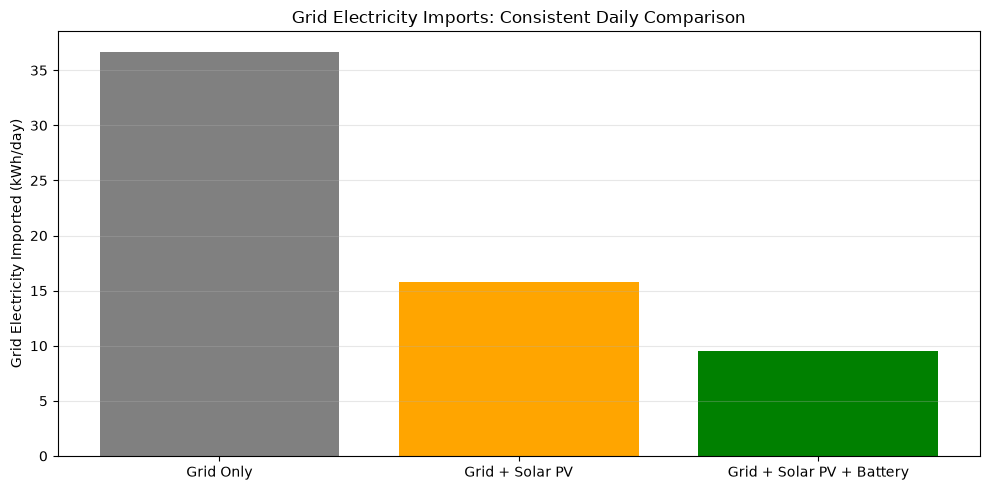

In [189]:

# Plot consistent daily grid electricity comparison

plt.figure(figsize=(10, 5))

plt.bar(
    fair_comparison["Scenario"],
    fair_comparison["Grid_Import_kWh"],
    color=["gray", "orange", "green"]
)

plt.ylabel("Grid Electricity Imported (kWh/day)")

plt.title(
    "Grid Electricity Imports: Consistent Daily Comparison"
)

plt.grid(True, axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_folder / "steady_day_grid_comparison.png",
    dpi=300
)

plt.show()


In [190]:

# Save improved simulation results

steady_day.to_csv(
    data_folder / "steady_day_simulation.csv",
    index=False
)

fair_comparison.to_csv(
    data_folder / "steady_day_scenario_comparison.csv",
    index=False
)

print("Improved simulation results saved successfully!")


Improved simulation results saved successfully!



## 10. Repeating-Day Simulation Results and Discussion

The initial battery simulation showed a reduction in stored energy from 5 kWh to 2 kWh over the simulated day.

To establish a more consistent comparison, the identical hourly solar-generation and electricity-demand profiles were repeated until the battery's initial and final stored energy values converged.

A consistent daily operating cycle was obtained with the battery beginning and ending at 20% state of charge.

### Results

The grid-only scenario required 36.70 kWh of grid electricity per day.

Adding solar PV without battery storage reduced grid imports to 15.82 kWh.

The combined solar PV–battery configuration further reduced grid imports to approximately 9.54 kWh.

This represented an approximate 74% reduction in grid electricity consumption relative to the grid-only scenario.

### Interpretation

The battery improved solar electricity utilisation by storing excess daytime generation for use during periods of insufficient solar production.

The repeating-day approach avoided attributing a recurring benefit to energy initially stored in the battery.

### Limitations

1. Electricity-demand and solar-generation profiles are hypothetical.
2. Identical conditions are assumed for every simulated day.
3. The results do not represent annual energy performance.
4. Battery ageing and detailed electrical constraints are not included.
5. The battery model does not include charging or discharging power limits.
6. The analysis represents an illustrative operating strategy rather than an optimised electrical system.

The improved simulation will provide the basis for subsequent economic, environmental and sensitivity analyses.



## 11. Techno-Economic Analysis

This section evaluates the illustrative economic performance of three electricity-supply configurations:

1. Grid-only electricity supply.
2. Grid-connected solar PV without battery storage.
3. Grid-connected solar PV with battery storage.

The analysis estimates electricity expenditure, annual operating costs, net operating savings and simple payback periods.

The repeating-day battery simulation provides the grid electricity-import values used for comparison.

All economic inputs are hypothetical and should not be interpreted as verified equipment quotations or actual electricity tariffs.

The analysis assumes that the representative daily electricity-demand and solar-generation profiles repeat for 365 days.


In [191]:

# Economic parameters (illustrative assumptions)

electricity_tariff = 200.0  # NGN/kWh

days_per_year = 365

# Initial capital investment (NGN)

pv_investment = 3_000_000

battery_additional_investment = 2_500_000

total_pv_battery_investment = (
    pv_investment + battery_additional_investment
)

# Annual operation and maintenance costs (NGN/year)

pv_maintenance = 30_000

battery_additional_maintenance = 25_000

total_pv_battery_maintenance = (
    pv_maintenance + battery_additional_maintenance
)

print("Illustrative economic parameters defined!")
print(f"Electricity tariff: NGN {electricity_tariff:,.2f}/kWh")
print(f"PV investment: NGN {pv_investment:,.2f}")
print(f"PV-battery investment: NGN {total_pv_battery_investment:,.2f}")


Illustrative economic parameters defined!
Electricity tariff: NGN 200.00/kWh
PV investment: NGN 3,000,000.00
PV-battery investment: NGN 5,500,000.00


In [192]:

# Calculate daily and annual grid electricity costs

economic_results = fair_comparison.copy()

# Daily electricity expenditure

economic_results["Daily_Grid_Cost_NGN"] = (
    economic_results["Grid_Import_kWh"]
    * electricity_tariff
)

# Annual electricity imports

economic_results["Annual_Grid_Import_kWh"] = (
    economic_results["Grid_Import_kWh"]
    * days_per_year
)

# Annual electricity expenditure

economic_results["Annual_Grid_Cost_NGN"] = (
    economic_results["Daily_Grid_Cost_NGN"]
    * days_per_year
)

# Display results

display(
    economic_results[
        [
            "Scenario",
            "Daily_Grid_Cost_NGN",
            "Annual_Grid_Cost_NGN"
        ]
    ].round(2)
)


,Scenario,Daily_Grid_Cost_NGN,Annual_Grid_Cost_NGN
0,Grid Only,7340.00,2679100.0
1,Grid + Solar PV,3164.00,1154860.0
2,Grid + Solar PV + Battery,1907.72,696317.8


In [193]:

# Define investment and annual maintenance costs

economic_results["Investment_NGN"] = [
    0,
    pv_investment,
    total_pv_battery_investment
]

economic_results["Annual_Maintenance_NGN"] = [
    0,
    pv_maintenance,
    total_pv_battery_maintenance
]

# Total annual operating expenditure
# Includes grid electricity and maintenance

economic_results["Annual_Operating_Cost_NGN"] = (
    economic_results["Annual_Grid_Cost_NGN"]
    + economic_results["Annual_Maintenance_NGN"]
)

# Grid-only annual cost is the baseline

baseline_annual_cost = economic_results.loc[
    economic_results["Scenario"] == "Grid Only",
    "Annual_Operating_Cost_NGN"
].iloc[0]

# Calculate annual net operating savings

economic_results["Annual_Net_Savings_NGN"] = (
    baseline_annual_cost
    - economic_results["Annual_Operating_Cost_NGN"]
)

display(
    economic_results[
        [
            "Scenario",
            "Annual_Operating_Cost_NGN",
            "Annual_Net_Savings_NGN"
        ]
    ].round(2)
)


,Scenario,Annual_Operating_Cost_NGN,Annual_Net_Savings_NGN
0,Grid Only,2679100.0,0.0
1,Grid + Solar PV,1184860.0,1494240.0
2,Grid + Solar PV + Battery,751317.8,1927782.2


In [194]:

# Calculate simple payback periods

def calculate_payback(investment, annual_savings):

    if annual_savings <= 0:
        return np.nan

    return investment / annual_savings

economic_results["Payback_Years"] = [
    calculate_payback(
        investment,
        savings
    )
    for investment, savings in zip(
        economic_results["Investment_NGN"],
        economic_results["Annual_Net_Savings_NGN"]
    )
]

display(
    economic_results[
        [
            "Scenario",
            "Investment_NGN",
            "Annual_Net_Savings_NGN",
            "Payback_Years"
        ]
    ].round(2)
)


,Scenario,Investment_NGN,Annual_Net_Savings_NGN,Payback_Years
0,Grid Only,0,0.0,NaN
1,Grid + Solar PV,3000000,1494240.0,2.01
2,Grid + Solar PV + Battery,5500000,1927782.2,2.85


In [195]:

# Evaluate the incremental battery investment

pv_annual_savings = economic_results.loc[
    economic_results["Scenario"] == "Grid + Solar PV",
    "Annual_Net_Savings_NGN"
].iloc[0]

pv_battery_annual_savings = economic_results.loc[
    economic_results["Scenario"] == "Grid + Solar PV + Battery",
    "Annual_Net_Savings_NGN"
].iloc[0]

# Additional annual savings provided by battery

incremental_battery_savings = (
    pv_battery_annual_savings
    - pv_annual_savings
)

# Incremental battery simple payback

incremental_battery_payback = calculate_payback(
    battery_additional_investment,
    incremental_battery_savings
)

print(
    f"Additional annual battery savings: "
    f"NGN {incremental_battery_savings:,.2f}"
)

print(
    f"Incremental battery payback: "
    f"{incremental_battery_payback:.2f} years"
)


Additional annual battery savings: NGN 433,542.20
Incremental battery payback: 5.77 years


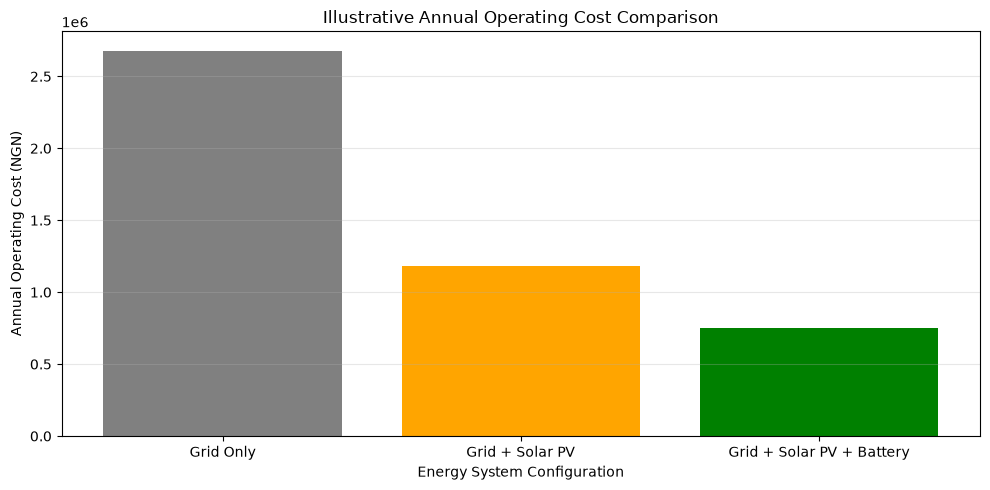

In [196]:

# Plot annual operating costs

plt.figure(figsize=(10, 5))

plt.bar(
    economic_results["Scenario"],
    economic_results["Annual_Operating_Cost_NGN"],
    color=["gray", "orange", "green"]
)

plt.xlabel("Energy System Configuration")
plt.ylabel("Annual Operating Cost (NGN)")

plt.title("Illustrative Annual Operating Cost Comparison")

plt.grid(True, axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_folder / "annual_operating_cost_comparison.png",
    dpi=300
)

plt.show()


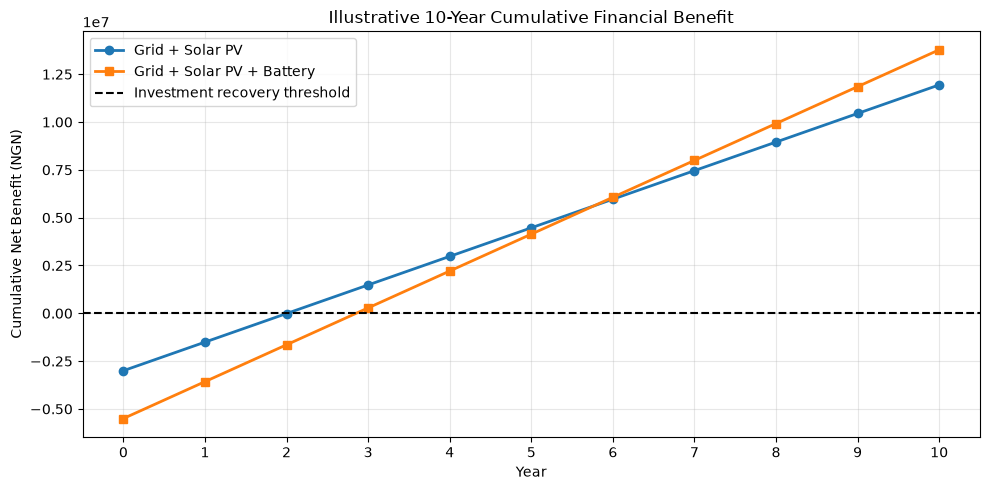

In [197]:

# Calculate cumulative financial benefits over 10 years

years = np.arange(0, 11)

pv_cumulative_benefit = (
    pv_annual_savings * years
    - pv_investment
)

pv_battery_cumulative_benefit = (
    pv_battery_annual_savings * years
    - total_pv_battery_investment
)

# Plot cumulative benefits

plt.figure(figsize=(10, 5))

plt.plot(
    years,
    pv_cumulative_benefit,
    marker="o",
    linewidth=2,
    label="Grid + Solar PV"
)

plt.plot(
    years,
    pv_battery_cumulative_benefit,
    marker="s",
    linewidth=2,
    label="Grid + Solar PV + Battery"
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    label="Investment recovery threshold"
)

plt.xlabel("Year")
plt.ylabel("Cumulative Net Benefit (NGN)")

plt.title(
    "Illustrative 10-Year Cumulative Financial Benefit"
)

plt.xticks(years)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    figures_folder / "cumulative_financial_benefit.png",
    dpi=300
)

plt.show()


In [198]:

# Verify economic model calculations

assert np.isclose(
    electricity_tariff,
    200.0
)

assert np.isclose(
    economic_results.loc[
        economic_results["Scenario"] == "Grid Only",
        "Annual_Grid_Cost_NGN"
    ].iloc[0],
    2_679_100
)

assert np.isclose(
    pv_annual_savings,
    1_494_240
)

assert np.isclose(
    incremental_battery_savings,
    433_542.20
)

assert np.isclose(
    economic_results.loc[
        economic_results["Scenario"] == "Grid + Solar PV",
        "Payback_Years"
    ].iloc[0],
    2.0077096049,
    atol=1e-6
)

assert np.isclose(
    incremental_battery_payback,
    5.7664513397,
    atol=1e-6
)

print("Economic model verification completed successfully!")


Economic model verification completed successfully!


In [199]:

# Save techno-economic analysis results

economic_results.to_csv(
    data_folder / "techno_economic_results.csv",
    index=False
)

# Save cumulative financial benefit data

cumulative_results = pd.DataFrame({
    "Year": years,
    "PV_Cumulative_Benefit_NGN": pv_cumulative_benefit,
    "PV_Battery_Cumulative_Benefit_NGN": (
        pv_battery_cumulative_benefit
    )
})

cumulative_results.to_csv(
    data_folder / "cumulative_financial_benefit.csv",
    index=False
)

print("Techno-economic results saved successfully!")


Techno-economic results saved successfully!



## 12. Techno-Economic Results and Discussion

A simplified techno-economic assessment was conducted for three hypothetical electricity-supply configurations: grid-only, grid-connected solar PV, and grid-connected solar PV with battery storage.

### Economic Assumptions

An illustrative electricity tariff of NGN 200/kWh was adopted.

The initial solar PV investment was assumed to be NGN 3,000,000, with an additional NGN 2,500,000 required for battery storage and integration.

Annual maintenance costs were assumed to be NGN 30,000 for the PV system and an additional NGN 25,000 for the battery system.

The repeating-day energy results were extended to 365 identical days to estimate annual performance.

### Results

Annual electricity expenditure was approximately NGN 2,679,100 for the grid-only scenario, NGN 1,154,860 for the PV-only scenario, and NGN 696,317.80 for the PV-battery scenario.

After including assumed annual maintenance costs, the PV-only and PV-battery systems provided estimated annual net operating savings of NGN 1,494,240 and NGN 1,927,782.20, respectively.

The corresponding simple payback periods were approximately 2.01 years for the PV-only configuration and 2.85 years for the combined PV-battery configuration.

The additional battery investment generated approximately NGN 433,542.20 in extra annual net operating savings relative to PV alone, resulting in an incremental simple payback period of approximately 5.77 years.

### Discussion

The PV-battery system achieved the lowest annual operating cost and the greatest reduction in grid electricity dependence.

However, the PV-only system provided a shorter simple payback period due to its lower initial investment cost.

These findings illustrate the trade-off between energy-system performance and capital investment.

### Limitations

1. All financial inputs are hypothetical.
2. Equipment costs are not based on verified supplier quotations.
3. Electricity tariffs are assumed constant.
4. Identical daily operating conditions are repeated throughout the year.
5. Battery replacement and performance degradation are not considered.
6. Financing costs, inflation, taxes and discount rates are excluded.
7. Simple payback is not a substitute for a full lifecycle financial assessment.
8. Actual economic performance requires location-specific demand, solar-resource data and verified cost information.

The results should therefore be interpreted as an illustrative techno-economic comparison rather than a prediction of actual investment profitability.



## 13. Environmental Impact Analysis

This section estimates grid-related operational carbon dioxide emissions for three hypothetical electricity-supply configurations:

1. Grid-only electricity supply.
2. Grid-connected solar PV.
3. Grid-connected solar PV with battery storage.

The analysis uses grid electricity-import results from the repeating-day simulation and an assumed electricity emissions factor.

The objective is to estimate the potential reduction in grid-related operational CO2 emissions associated with solar PV generation and battery storage.

An illustrative grid emissions factor of 0.45 kg CO2/kWh is adopted.

This value is a modelling assumption and does not represent a verified national electricity emissions factor.

The analysis excludes manufacturing, installation, replacement and end-of-life emissions from solar PV and battery equipment.


In [200]:

# Environmental modelling assumptions

# Illustrative grid emissions factor
grid_emissions_factor = 0.45  # kg CO2/kWh

# Annual operating period
days_per_year = 365

# Create environmental results table
# Using the fair scenario comparison from Day 2 Task 1

emissions_results = fair_comparison[
    ["Scenario", "Grid_Import_kWh"]
].copy()

print("Environmental parameters defined successfully!")

print(
    f"Assumed grid emissions factor: "
    f"{grid_emissions_factor:.2f} kg CO2/kWh"
)

display(emissions_results)


Environmental parameters defined successfully!
Assumed grid emissions factor: 0.45 kg CO2/kWh


,Scenario,Grid_Import_kWh
0,Grid Only,36.7000
1,Grid + Solar PV,15.8200
2,Grid + Solar PV + Battery,9.5386


In [201]:

# Calculate daily grid-related CO2 emissions

emissions_results["Daily_CO2_kg"] = (
    emissions_results["Grid_Import_kWh"]
    * grid_emissions_factor
)

# Calculate annual CO2 emissions in kilograms

emissions_results["Annual_CO2_kg"] = (
    emissions_results["Daily_CO2_kg"]
    * days_per_year
)

# Convert annual emissions from kg to tonnes

emissions_results["Annual_CO2_tonnes"] = (
    emissions_results["Annual_CO2_kg"] / 1000
)

# Display results

display(
    emissions_results[
        [
            "Scenario",
            "Daily_CO2_kg",
            "Annual_CO2_tonnes"
        ]
    ].round(3)
)


,Scenario,Daily_CO2_kg,Annual_CO2_tonnes
0,Grid Only,16.515,6.028
1,Grid + Solar PV,7.119,2.598
2,Grid + Solar PV + Battery,4.292,1.567


In [202]:

# Identify baseline emissions

baseline_daily_co2 = emissions_results.loc[
    emissions_results["Scenario"] == "Grid Only",
    "Daily_CO2_kg"
].iloc[0]

baseline_annual_co2 = emissions_results.loc[
    emissions_results["Scenario"] == "Grid Only",
    "Annual_CO2_tonnes"
].iloc[0]

# Calculate daily avoided emissions

emissions_results["Daily_Avoided_CO2_kg"] = (
    baseline_daily_co2
    - emissions_results["Daily_CO2_kg"]
)

# Calculate annual avoided emissions

emissions_results["Annual_Avoided_CO2_tonnes"] = (
    baseline_annual_co2
    - emissions_results["Annual_CO2_tonnes"]
)

# Calculate percentage reduction

emissions_results["CO2_Reduction_pct"] = (
    emissions_results["Daily_Avoided_CO2_kg"]
    / baseline_daily_co2
    * 100
)

# Display results

display(
    emissions_results[
        [
            "Scenario",
            "Annual_Avoided_CO2_tonnes",
            "CO2_Reduction_pct"
        ]
    ].round(2)
)


,Scenario,Annual_Avoided_CO2_tonnes,CO2_Reduction_pct
0,Grid Only,0.00,0.00
1,Grid + Solar PV,3.43,56.89
2,Grid + Solar PV + Battery,4.46,74.01


In [203]:

# Calculate additional emissions reduction from battery storage

pv_annual_co2 = emissions_results.loc[
    emissions_results["Scenario"] == "Grid + Solar PV",
    "Annual_CO2_tonnes"
].iloc[0]

pv_battery_annual_co2 = emissions_results.loc[
    emissions_results["Scenario"] == "Grid + Solar PV + Battery",
    "Annual_CO2_tonnes"
].iloc[0]

# Additional avoided CO2 emissions

additional_battery_co2_savings = (
    pv_annual_co2 - pv_battery_annual_co2
)

print(
    f"Additional avoided emissions from battery: "
    f"{additional_battery_co2_savings:.3f} tonnes CO2/year"
)


Additional avoided emissions from battery: 1.032 tonnes CO2/year


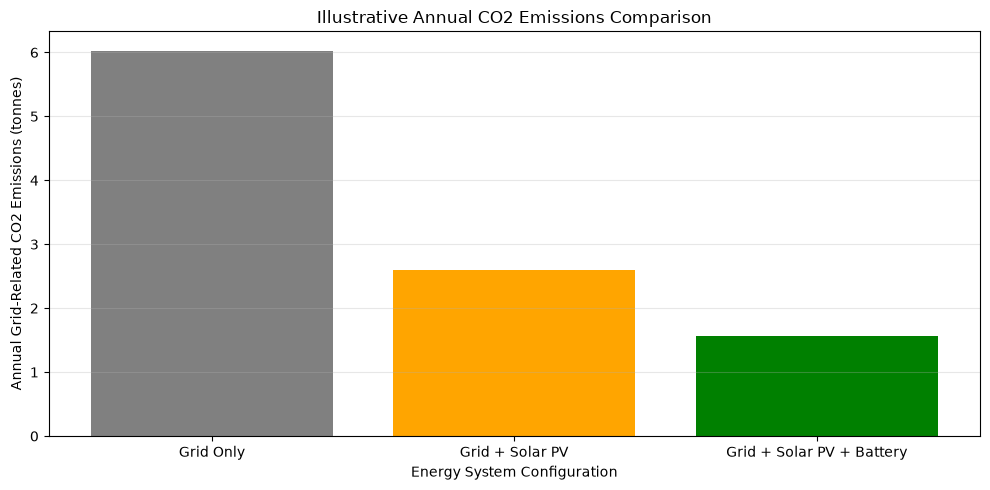

In [204]:

# Plot estimated annual CO2 emissions

plt.figure(figsize=(10, 5))

plt.bar(
    emissions_results["Scenario"],
    emissions_results["Annual_CO2_tonnes"],
    color=["gray", "orange", "green"]
)

plt.xlabel("Energy System Configuration")
plt.ylabel("Annual Grid-Related CO2 Emissions (tonnes)")

plt.title("Illustrative Annual CO2 Emissions Comparison")

plt.grid(True, axis="y", alpha=0.3)

plt.tight_layout()

# Save graph

plt.savefig(
    figures_folder / "annual_co2_emissions_comparison.png",
    dpi=300
)

plt.show()


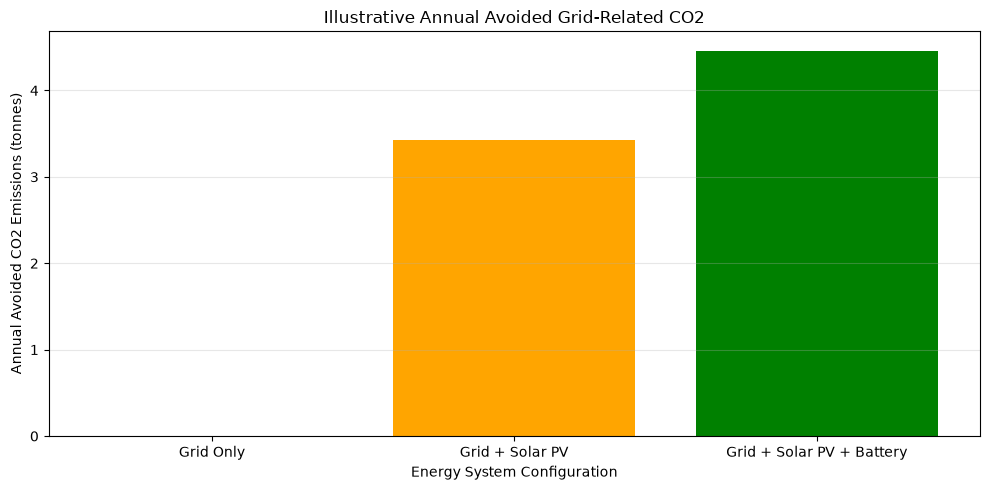

In [205]:

# Plot annual avoided CO2 emissions

plt.figure(figsize=(10, 5))

plt.bar(
    emissions_results["Scenario"],
    emissions_results["Annual_Avoided_CO2_tonnes"],
    color=["gray", "orange", "green"]
)

plt.xlabel("Energy System Configuration")
plt.ylabel("Annual Avoided CO2 Emissions (tonnes)")

plt.title("Illustrative Annual Avoided Grid-Related CO2")

plt.grid(True, axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_folder / "annual_avoided_co2_emissions.png",
    dpi=300
)

plt.show()


In [206]:

# Verify environmental analysis

# Emissions must not be negative
assert (
    emissions_results["Daily_CO2_kg"] >= 0
).all()

# Verify emissions-factor calculation
np.testing.assert_allclose(
    emissions_results["Daily_CO2_kg"],
    emissions_results["Grid_Import_kWh"]
    * grid_emissions_factor,
    atol=1e-9
)

# Verify emissions balance relative to baseline
np.testing.assert_allclose(
    emissions_results["Daily_CO2_kg"]
    + emissions_results["Daily_Avoided_CO2_kg"],
    baseline_daily_co2,
    atol=1e-9
)

# Verify grid-only baseline
assert np.isclose(
    baseline_daily_co2,
    16.515
)

# Verify PV-only annual emissions
assert np.isclose(
    pv_annual_co2,
    2.598435
)

# Verify PV-battery annual emissions
assert np.isclose(
    pv_battery_annual_co2,
    1.56671505
)

print("Environmental model verification successful!")


Environmental model verification successful!


In [207]:

# Save environmental analysis results

emissions_results.to_csv(
    data_folder / "environmental_impact_results.csv",
    index=False
)

print("Environmental results saved successfully!")


Environmental results saved successfully!



## 14. Environmental Impact Results and Discussion

A simplified environmental assessment was performed to estimate grid-related operational carbon dioxide emissions for the three hypothetical electricity-supply scenarios.

An illustrative grid electricity emissions factor of 0.45 kg CO2/kWh was adopted.

The energy results from the consistent repeating-day simulation were used to estimate daily and annual emissions.

### Results

The grid-only scenario produced estimated emissions of approximately 6.028 tonnes CO2 per year.

Introducing solar PV reduced estimated grid-related operational emissions to 2.598 tonnes CO2 per year.

The combined solar PV-battery configuration further reduced estimated grid-related operational emissions to 1.567 tonnes CO2 per year.

Relative to the grid-only scenario, the PV-only system produced an estimated emissions reduction of 56.89%, while the combined PV-battery system achieved an estimated reduction of 74.01%.

The additional battery storage was associated with approximately 1.032 tonnes of avoided grid-related CO2 emissions per year relative to the PV-only system.

### Discussion

Solar PV generation reduced the building's dependence on utility grid electricity.

Battery storage further reduced grid electricity imports by shifting surplus solar energy to periods of insufficient solar generation.

Under the assumed constant grid emissions factor, reductions in grid electricity consumption produced proportional reductions in grid-related operational CO2 emissions.

### Limitations

1. The grid emissions factor is hypothetical.
2. Identical operating conditions are assumed throughout the year.
3. Solar PV and battery manufacturing emissions are excluded.
4. Equipment replacement, maintenance-related emissions and end-of-life impacts are excluded.
5. Hourly changes in grid emissions intensity are not considered.
6. The analysis does not represent a complete lifecycle assessment.
7. Actual avoided emissions depend on the electricity generation displaced by the renewable energy system.

The results demonstrate the potential contribution of solar PV and battery storage to reducing grid-related operational emissions under clearly stated modelling assumptions.



## 15. Sensitivity Analysis

This section investigates the influence of solar PV capacity and battery storage size on the performance of the hypothetical grid-connected PV-battery system.

Two separate parameter studies are conducted.

### Analysis A: Solar PV Capacity

Solar PV capacity is varied between 0 and 10 kWp while battery capacity remains fixed at 10 kWh.

### Analysis B: Battery Storage Capacity

Battery capacity is varied between 0 and 20 kWh while solar PV capacity remains fixed at 5 kWp.

The same illustrative building electricity-demand and solar irradiance profiles are retained.

Each configuration is evaluated using a repeating-day simulation with consistent initial and final battery energy.

The analysis investigates daily grid electricity imports, solar curtailment, annual operating costs, grid-related CO2 emissions and illustrative simple payback periods.

All parameter values and financial assumptions are hypothetical.


In [208]:

# Sensitivity Analysis
# Flexible hourly battery simulation

def simulate_sensitivity_day(
    demand_profile,
    pv_profile,
    battery_capacity,
    initial_energy
):

    # Battery assumptions
    min_energy = 0.20 * battery_capacity
    max_energy = 0.90 * battery_capacity

    eta_charge = 0.95
    eta_discharge = 0.95

    stored_energy = initial_energy

    results = []

    for hour in range(len(demand_profile)):

        demand = float(demand_profile[hour])
        pv = float(pv_profile[hour])

        # 1. Solar PV supplies the building first
        pv_direct = min(demand, pv)

        surplus_pv = max(0.0, pv - pv_direct)
        unmet_demand = max(0.0, demand - pv_direct)

        # 2. Charge the battery with surplus PV
        available_charge_input = max(
            0.0,
            (max_energy - stored_energy) / eta_charge
        )

        pv_to_battery = min(
            surplus_pv,
            available_charge_input
        )

        stored_energy += pv_to_battery * eta_charge

        # 3. Discharge battery when needed
        available_discharge = max(
            0.0,
            (stored_energy - min_energy) * eta_discharge
        )

        battery_to_load = min(
            unmet_demand,
            available_discharge
        )

        stored_energy -= battery_to_load / eta_discharge

        # 4. Grid supplies remaining demand
        grid_import = max(
            0.0,
            unmet_demand - battery_to_load
        )

        # 5. Calculate unused solar energy
        pv_curtailed = max(
            0.0,
            surplus_pv - pv_to_battery
        )

        # 6. Record battery energy losses
        charging_loss = (
            pv_to_battery * (1 - eta_charge)
        )

        discharging_loss = (
            battery_to_load * (1 / eta_discharge - 1)
        )

        results.append({
            "Hour": hour,
            "Demand_kWh": demand,
            "PV_Generation_kWh": pv,
            "PV_to_Load_kWh": pv_direct,
            "PV_to_Battery_kWh": pv_to_battery,
            "Battery_to_Load_kWh": battery_to_load,
            "Grid_Import_kWh": grid_import,
            "PV_Curtailed_kWh": pv_curtailed,
            "Battery_End_kWh": stored_energy,
            "Charge_Loss_kWh": charging_loss,
            "Discharge_Loss_kWh": discharging_loss
        })

    return pd.DataFrame(results)


print("Flexible sensitivity simulation function created!")


Flexible sensitivity simulation function created!


In [209]:

# Evaluate any PV-battery system configuration

def evaluate_configuration(pv_kwp, battery_kwh):

    if pv_kwp < 0 or battery_kwh < 0:
        raise ValueError("System capacities cannot be negative.")

    # Retrieve our original hourly profiles
    demand = energy_data["Demand_kWh"].to_numpy(
        dtype=float
    )

    irradiance = energy_data["Irradiance_Wm2"].to_numpy(
        dtype=float
    )

    # Calculate PV generation for the selected capacity
    pv_profile = (
        pv_kwp * (irradiance / 1000) * 0.80
    )

    # Begin with 50% nominal battery capacity
    start_energy = 0.50 * battery_kwh

    # Find the repeating-day operating cycle
    for cycle in range(1, 31):

        simulation = simulate_sensitivity_day(
            demand,
            pv_profile,
            battery_kwh,
            start_energy
        )

        end_energy = float(
            simulation["Battery_End_kWh"].iloc[-1]
        )

        if np.isclose(
            start_energy, end_energy,
            atol=1e-9, rtol=0
        ):
            break

        start_energy = end_energy

    else:
        raise RuntimeError(
            "Repeating-day condition did not converge."
        )

    # Verify the electricity-demand balance
    np.testing.assert_allclose(
        simulation["Demand_kWh"],
        simulation["PV_to_Load_kWh"]
        + simulation["Battery_to_Load_kWh"]
        + simulation["Grid_Import_kWh"],
        atol=1e-9
    )

    # Verify the solar PV balance
    np.testing.assert_allclose(
        simulation["PV_Generation_kWh"],
        simulation["PV_to_Load_kWh"]
        + simulation["PV_to_Battery_kWh"]
        + simulation["PV_Curtailed_kWh"],
        atol=1e-9
    )

    # Verify total energy conservation
    total_input = (
        pv_profile.sum()
        + simulation["Grid_Import_kWh"].sum()
        + start_energy
    )

    total_output = (
        demand.sum()
        + simulation["PV_Curtailed_kWh"].sum()
        + simulation["Charge_Loss_kWh"].sum()
        + simulation["Discharge_Loss_kWh"].sum()
        + end_energy
    )

    assert np.isclose(
        total_input, total_output, atol=1e-9
    )

    # Calculate daily energy quantities
    daily_grid = simulation["Grid_Import_kWh"].sum()

    curtailed_pv = simulation["PV_Curtailed_kWh"].sum()

    # Annual grid electricity expenditure
    annual_grid_cost = daily_grid * 200 * 365

    # Annual grid-related emissions (tonnes CO2)
    annual_co2 = daily_grid * 0.45 * 365 / 1000

    # Illustrative capital cost scaling
    investment = (
        (pv_kwp / 5) * 3_000_000
        + (battery_kwh / 10) * 2_500_000
    )

    # Illustrative annual maintenance cost scaling
    maintenance = (
        (pv_kwp / 5) * 30_000
        + (battery_kwh / 10) * 25_000
    )

    # Total annual operating expenditure
    annual_operating_cost = annual_grid_cost + maintenance

    # Annual grid-only reference cost
    baseline_cost = demand.sum() * 200 * 365

    annual_savings = (
        baseline_cost - annual_operating_cost
    )

    # Simple payback
    if annual_savings > 0 and investment > 0:
        payback = investment / annual_savings
    else:
        payback = np.nan

    return {
        "PV_kWp": pv_kwp,
        "Battery_kWh": battery_kwh,
        "Grid_kWh_day": daily_grid,
        "PV_Curtailed_kWh_day": curtailed_pv,
        "Annual_Grid_Cost_NGN": annual_grid_cost,
        "Annual_Operating_Cost_NGN": annual_operating_cost,
        "Annual_CO2_tonnes": annual_co2,
        "Investment_NGN": investment,
        "Annual_Net_Savings_NGN": annual_savings,
        "Payback_years": payback
    }


print("Configuration evaluation function created!")


Configuration evaluation function created!


In [210]:

# Test our original 5 kWp PV and 10 kWh battery system

original_configuration = evaluate_configuration(
    pv_kwp=5,
    battery_kwh=10
)

display(
    pd.DataFrame([original_configuration]).round(2)
)


,PV_kWp,Battery_kWh,Grid_kWh_day,PV_Curtailed_kWh_day,Annual_Grid_Cost_NGN,Annual_Operating_Cost_NGN,Annual_CO2_tonnes,Investment_NGN,Annual_Net_Savings_NGN,Payback_years
0,5,10,9.54,0.0,696317.8,751317.8,1.57,5500000.0,1927782.2,2.85


In [211]:

# Sensitivity Analysis A
# Vary PV capacity with battery fixed at 10 kWh

pv_capacities = [0, 2.5, 5, 7.5, 10]

pv_results = []

for pv_size in pv_capacities:

    result = evaluate_configuration(
        pv_kwp=pv_size,
        battery_kwh=10
    )

    pv_results.append(result)

# Convert results to DataFrame
pv_sensitivity = pd.DataFrame(pv_results)

# Display selected results
display(
    pv_sensitivity[
        [
            "PV_kWp",
            "Grid_kWh_day",
            "PV_Curtailed_kWh_day",
            "Annual_Operating_Cost_NGN",
            "Annual_CO2_tonnes",
            "Payback_years"
        ]
    ].round(2)
)


,PV_kWp,Grid_kWh_day,PV_Curtailed_kWh_day,Annual_Operating_Cost_NGN,Annual_CO2_tonnes,Payback_years
0,0.0,36.70,0.00,2704100.0,6.03,NaN
1,2.5,22.78,0.00,1702940.0,3.74,4.10
2,5.0,9.54,0.00,751317.8,1.57,2.85
3,7.5,7.83,12.17,641590.0,1.29,3.44
4,10.0,7.09,25.35,602570.0,1.16,4.09


In [212]:

# Sensitivity Analysis B
# Vary battery capacity with PV fixed at 5 kWp

battery_capacities = [0, 5, 10, 15, 20]

battery_results = []

for battery_size in battery_capacities:

    result = evaluate_configuration(
        pv_kwp=5,
        battery_kwh=battery_size
    )

    battery_results.append(result)

# Convert results to DataFrame
battery_sensitivity = pd.DataFrame(battery_results)

# Display selected results
display(
    battery_sensitivity[
        [
            "Battery_kWh",
            "Grid_kWh_day",
            "PV_Curtailed_kWh_day",
            "Annual_Operating_Cost_NGN",
            "Annual_CO2_tonnes",
            "Payback_years"
        ]
    ].round(2)
)


,Battery_kWh,Grid_kWh_day,PV_Curtailed_kWh_day,Annual_Operating_Cost_NGN,Annual_CO2_tonnes,Payback_years
0,0,15.82,6.96,1184860.0,2.60,2.01
1,5,12.49,3.28,954635.0,2.05,2.46
2,10,9.54,0.00,751317.8,1.57,2.85
3,15,9.54,0.00,763817.8,1.57,3.52
4,20,9.54,0.00,776317.8,1.57,4.20


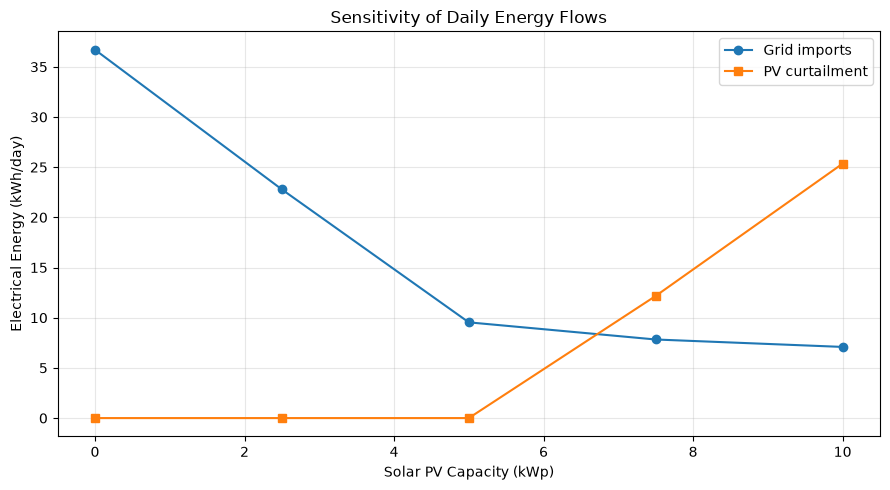

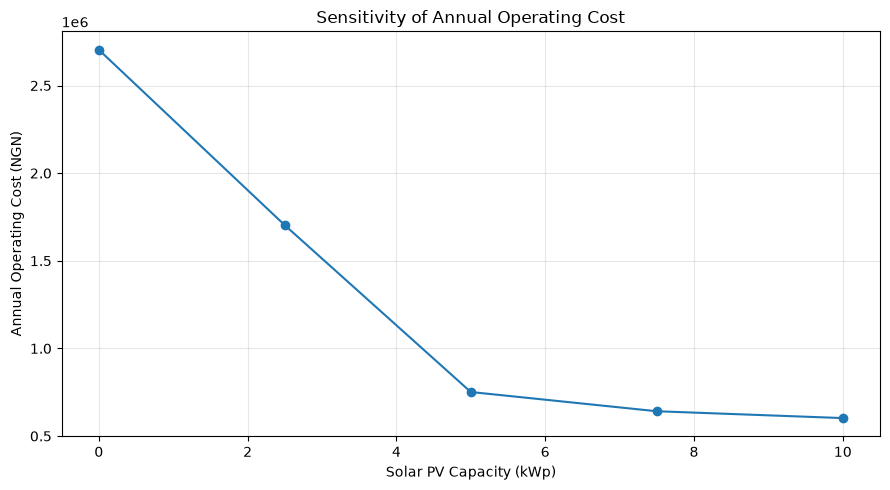

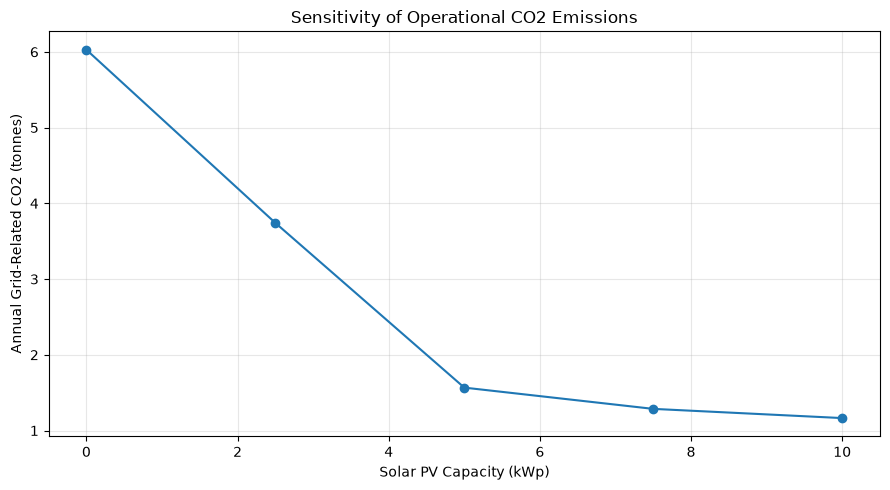

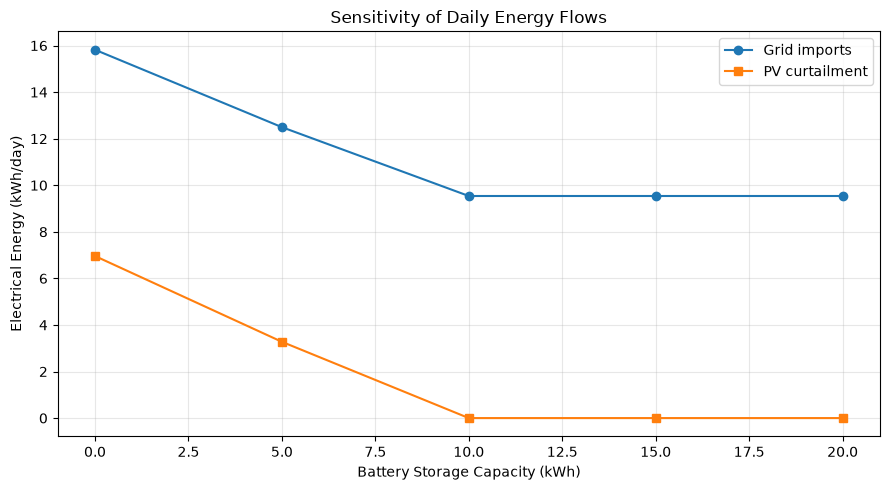

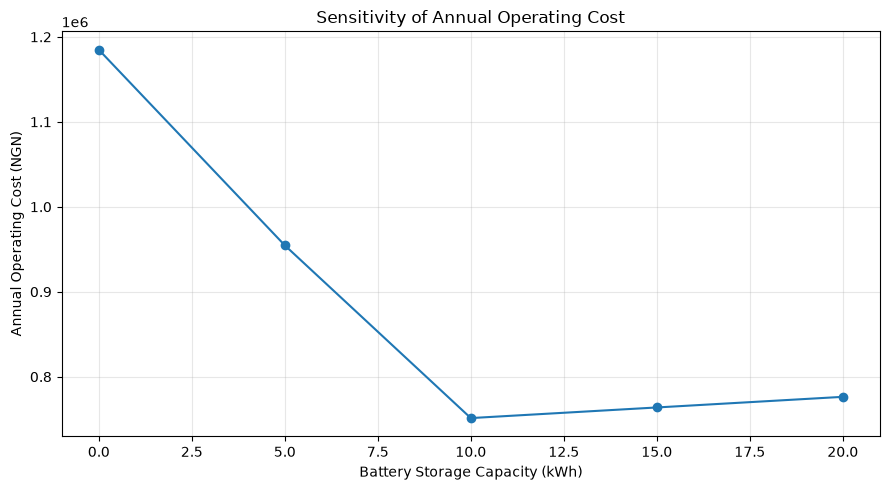

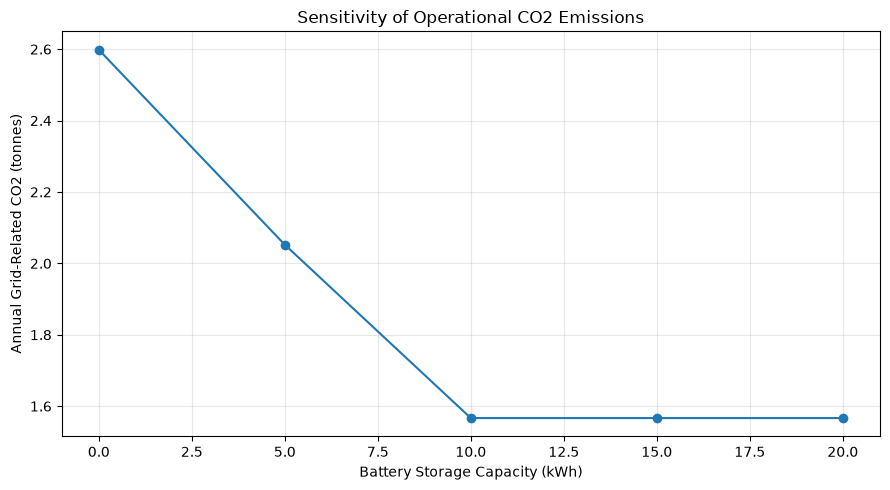

Sensitivity analysis graphs generated successfully!


In [213]:

# Generate sensitivity analysis graphs

analysis_sets = [
    (
        pv_sensitivity,
        "PV_kWp",
        "Solar PV Capacity (kWp)",
        "pv_capacity"
    ),
    (
        battery_sensitivity,
        "Battery_kWh",
        "Battery Storage Capacity (kWh)",
        "battery_capacity"
    )
]

for df, x_column, x_label, file_name in analysis_sets:

    # Graph 1: Daily grid imports and PV curtailment
    plt.figure(figsize=(9, 5))

    plt.plot(
        df[x_column],
        df["Grid_kWh_day"],
        marker="o",
        label="Grid imports"
    )

    plt.plot(
        df[x_column],
        df["PV_Curtailed_kWh_day"],
        marker="s",
        label="PV curtailment"
    )

    plt.xlabel(x_label)
    plt.ylabel("Electrical Energy (kWh/day)")
    plt.title("Sensitivity of Daily Energy Flows")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        figures_folder / f"sensitivity_{file_name}_energy.png",
        dpi=300
    )

    plt.show()

    # Graph 2: Annual operating cost
    plt.figure(figsize=(9, 5))

    plt.plot(
        df[x_column],
        df["Annual_Operating_Cost_NGN"],
        marker="o"
    )

    plt.xlabel(x_label)
    plt.ylabel("Annual Operating Cost (NGN)")
    plt.title("Sensitivity of Annual Operating Cost")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        figures_folder / f"sensitivity_{file_name}_cost.png",
        dpi=300
    )

    plt.show()

    # Graph 3: Annual grid-related CO2 emissions
    plt.figure(figsize=(9, 5))

    plt.plot(
        df[x_column],
        df["Annual_CO2_tonnes"],
        marker="o"
    )

    plt.xlabel(x_label)
    plt.ylabel("Annual Grid-Related CO2 (tonnes)")
    plt.title("Sensitivity of Operational CO2 Emissions")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        figures_folder / f"sensitivity_{file_name}_co2.png",
        dpi=300
    )

    plt.show()

print("Sensitivity analysis graphs generated successfully!")


In [214]:

# Verify sensitivity analysis results

# Original configuration: 5 kWp PV and 10 kWh battery
reference_system = evaluate_configuration(5, 10)

assert np.isclose(
    reference_system["Grid_kWh_day"],
    9.5386,
    atol=1e-9
)

# PV-only reference: 5 kWp PV and zero battery
pv_only_system = evaluate_configuration(5, 0)

assert np.isclose(
    pv_only_system["Grid_kWh_day"],
    15.82,
    atol=1e-9
)

# Grid-only reference
grid_only_system = evaluate_configuration(0, 0)

assert np.isclose(
    grid_only_system["Grid_kWh_day"],
    36.70,
    atol=1e-9
)

# Increasing PV capacity should not increase
# grid imports in this particular model
assert (
    np.diff(pv_sensitivity["Grid_kWh_day"]) <= 1e-9
).all()

# Increasing battery capacity should not increase
# grid imports in this particular model
assert (
    np.diff(battery_sensitivity["Grid_kWh_day"]) <= 1e-9
).all()

# Verify that both studies reproduce
# the same original system configuration
pv_reference = pv_sensitivity.loc[
    pv_sensitivity["PV_kWp"] == 5,
    "Grid_kWh_day"
].iloc[0]

battery_reference = battery_sensitivity.loc[
    battery_sensitivity["Battery_kWh"] == 10,
    "Grid_kWh_day"
].iloc[0]

assert np.isclose(
    pv_reference,
    battery_reference,
    atol=1e-9
)

print("Sensitivity analysis verification successful!")


Sensitivity analysis verification successful!


In [215]:

# Save sensitivity analysis results

pv_sensitivity.to_csv(
    data_folder / "sensitivity_pv_capacity.csv",
    index=False
)

battery_sensitivity.to_csv(
    data_folder / "sensitivity_battery_capacity.csv",
    index=False
)

print("Sensitivity analysis datasets saved successfully!")


Sensitivity analysis datasets saved successfully!



## 16. Sensitivity Analysis Results and Discussion

A sensitivity analysis was conducted to investigate how solar PV capacity and battery storage size influence the performance of the hypothetical grid-connected energy system.

Two separate parameter studies were performed using the same illustrative hourly electricity-demand and solar irradiance profiles.

### Solar PV Capacity Analysis

Solar PV capacity was varied from 0 to 10 kWp while battery capacity remained fixed at 10 kWh.

Increasing PV capacity generally reduced grid electricity imports.

At 5 kWp, the combined system imported approximately 9.54 kWh of electricity per day.

Increasing PV capacity to 7.5 and 10 kWp further reduced grid imports to approximately 7.83 and 7.09 kWh/day, respectively.

However, larger PV capacities produced substantial surplus electricity that could not be consumed or stored.

This demonstrated diminishing benefits from increasing PV capacity under fixed building-demand and battery-storage conditions.

### Battery Capacity Analysis

Battery storage capacity was varied from 0 to 20 kWh while solar PV capacity remained fixed at 5 kWp.

Without battery storage, daily grid electricity imports were approximately 15.82 kWh.

Increasing battery capacity to 5 kWh reduced grid imports to approximately 12.50 kWh/day.

A 10 kWh battery further reduced grid imports to approximately 9.54 kWh/day.

Increasing battery capacity beyond 10 kWh produced no additional grid-import reduction for the assumed representative daily profiles.

### Economic Interpretation

The 10 kWh battery achieved the lowest annual operating cost among the tested battery configurations.

However, the 5 kWh battery had a shorter simple payback period because of its lower initial investment.

This demonstrated that improving energy performance does not necessarily minimise investment payback time.

### Environmental Interpretation

Configurations with lower grid electricity imports also produced lower estimated grid-related operational CO2 emissions under the assumed constant emissions factor.

These results do not represent complete lifecycle environmental impacts.

### Limitations

1. Building electricity demand and solar irradiance are hypothetical.
2. The sensitivity analysis uses a limited number of design configurations.
3. Identical daily operating conditions are assumed.
4. Battery charging and discharging power limits are excluded.
5. Capital and maintenance costs are assumed to scale linearly with capacity.
6. Battery ageing, replacement and lifecycle emissions are not included.
7. The analysis does not establish an optimal real-world system design.

### Conclusion

The sensitivity analysis demonstrated that solar PV capacity and battery storage size influence grid electricity consumption, solar curtailment, operating costs and estimated grid-related operational emissions.

The results highlight the importance of matching solar-generation capacity and battery storage to the electricity-demand profile rather than assuming that larger system capacities always provide proportionally greater benefits.
